# 03 – Bivariate Analysis and Conclusions

Here we look at how each feature relates to the price, figure out which ones matter most, spot any non-linear patterns, check for multicollinearity, and lay out what we plan to do in the modelling phase. We work with log(PRICE) since the raw price distribution is very skewed.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)

# Consistent visual style
sns.set_theme(style="whitegrid", palette="colorblind", font_scale=1.1)
plt.rcParams.update({"figure.dpi": 120, "axes.titlesize": 13, "axes.labelsize": 11})

PERIOD_MAP = {"201803": "Q1 2018", "201806": "Q2 2018", "201809": "Q3 2018", "201812": "Q4 2018"}

df = pd.read_parquet("../data/processed/listings_02.parquet")

df["log_price"] = np.log(df["PRICE"])
print(f"Loaded: {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"log(PRICE) — mean: {df['log_price'].mean():.2f}, std: {df['log_price'].std():.2f}")

Loaded: 75,795 rows × 39 columns
log(PRICE) — mean: 12.54, std: 0.76


## 1. Continuous features vs log(PRICE)

We plot each continuous feature against log(PRICE) with a trend line to see how strong and how linear the relationship is.

In [2]:
readable = {
    "CONSTRUCTEDAREA": "Constructed area (m2)",
    "CADCONSTRUCTIONYEAR": "Construction year",
    "DISTANCE_TO_CITY_CENTER": "Distance to city centre (km)",
    "DISTANCE_TO_METRO": "Distance to nearest metro (km)",
}

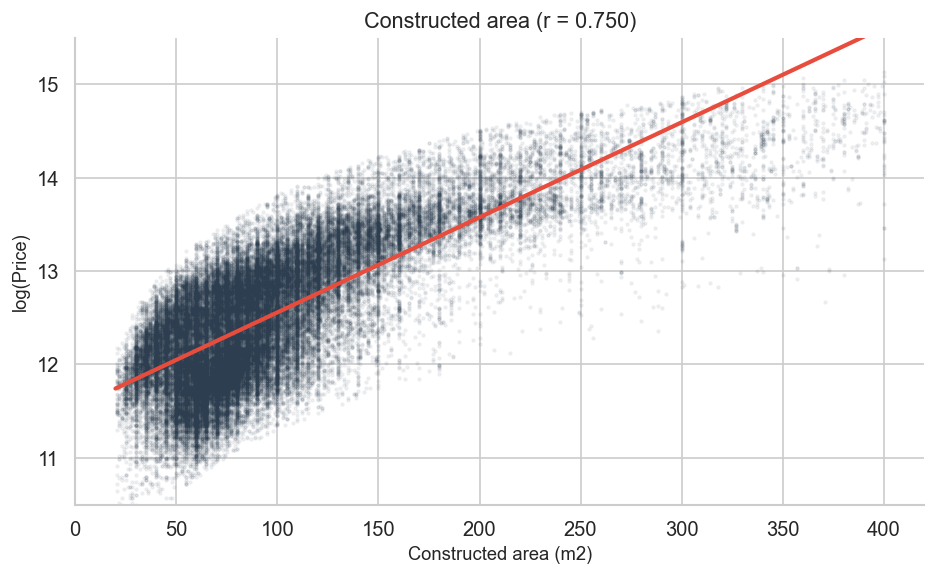

In [3]:
# Constructed area vs log(PRICE)
r = df["CONSTRUCTEDAREA"].corr(df["log_price"])
subset = df[df["CONSTRUCTEDAREA"] <= 400]

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(subset["CONSTRUCTEDAREA"], subset["log_price"],
           alpha=0.06, s=3, color="#2c3e50")
z = np.polyfit(subset["CONSTRUCTEDAREA"], subset["log_price"], 1)
x_line = np.linspace(20, 400, 100)
ax.plot(x_line, np.polyval(z, x_line), color="#e74c3c", lw=2.5)
ax.set_xlim(0, 420)
ax.set_ylim(10.5, 15.5)
ax.set_title(f"Constructed area (r = {r:.3f})")
ax.set_xlabel("Constructed area (m2)")
ax.set_ylabel("log(Price)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

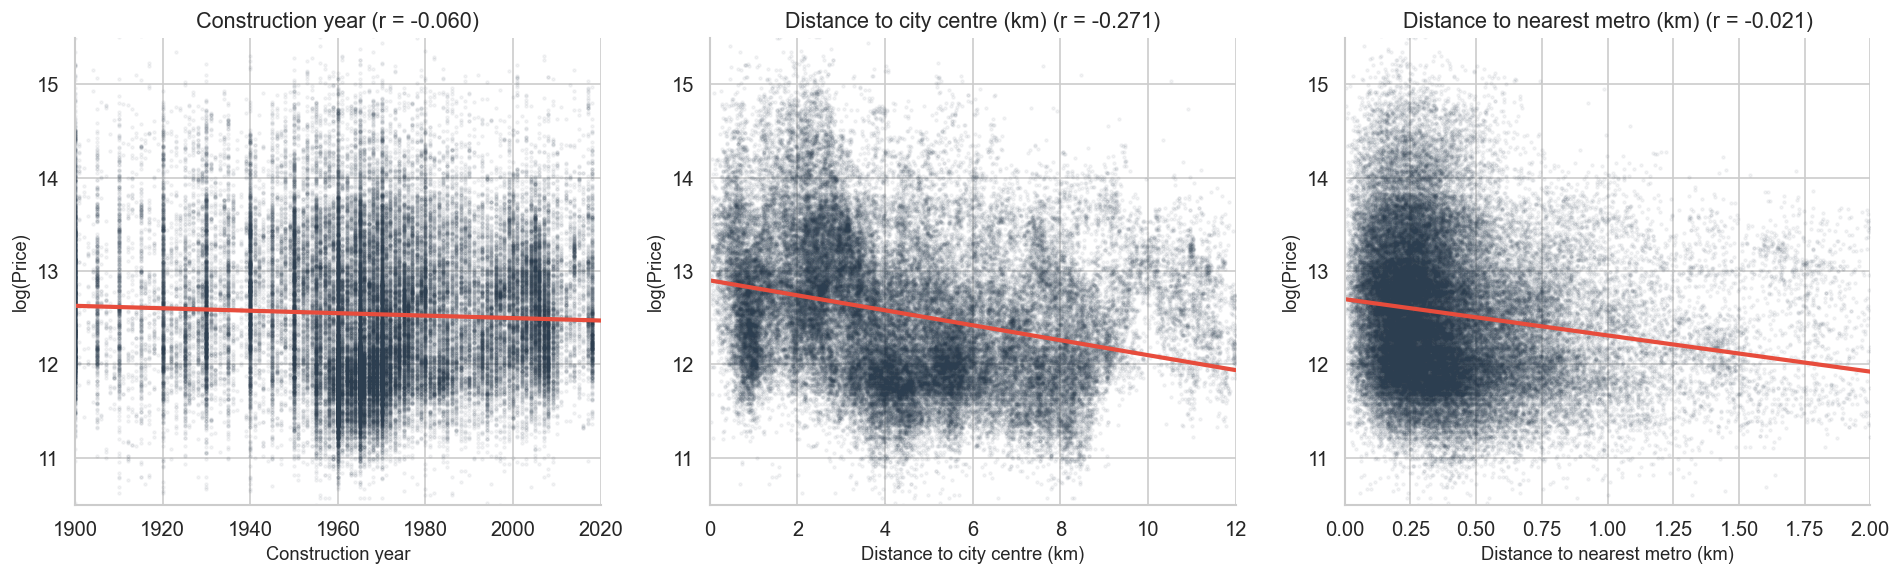

In [4]:
# Remaining continuous features vs log(PRICE)
other_features = ["CADCONSTRUCTIONYEAR", "DISTANCE_TO_CITY_CENTER", "DISTANCE_TO_METRO"]

xlims = {
    "CADCONSTRUCTIONYEAR": (1900, 2020),
    "DISTANCE_TO_CITY_CENTER": (0, 12),
    "DISTANCE_TO_METRO": (0, 2),
}

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, feat in zip(axes, other_features):
    lo, hi = xlims[feat]
    mask = df[feat].between(lo, hi)
    ax.scatter(df.loc[mask, feat], df.loc[mask, "log_price"],
               alpha=0.05, s=3, color="#2c3e50")
    z = np.polyfit(df.loc[mask, feat], df.loc[mask, "log_price"], 1)
    x_line = np.linspace(lo, hi, 100)
    ax.plot(x_line, np.polyval(z, x_line), color="#e74c3c", lw=2.5)
    r = df[feat].corr(df["log_price"])
    ax.set_xlim(lo, hi)
    ax.set_ylim(10.5, 15.5)
    ax.set_title(f"{readable[feat]} (r = {r:.3f})")
    ax.set_ylabel("log(Price)")
    ax.set_xlabel(readable[feat])
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

CONSTRUCTEDAREA is by far the strongest predictor (r = 0.75) — bigger flats cost more, as expected. Distance to the city centre has a moderate negative effect (r = -0.27).

CADCONSTRUCTIONYEAR is interesting: the linear correlation is almost zero (r = -0.06), but the plot shows a U-shape. Old pre-1900 buildings and new post-2000 ones are expensive, while the 1960s-80s housing estates are the cheapest. A linear model won't pick this up — we'll need bins or a tree-based model.

DISTANCE_TO_METRO barely matters linearly (r = -0.02), though there is a small monotonic effect.

## 2. Discrete and ordinal features vs log(PRICE)

For discrete variables we use boxplots to see how price changes across each level.

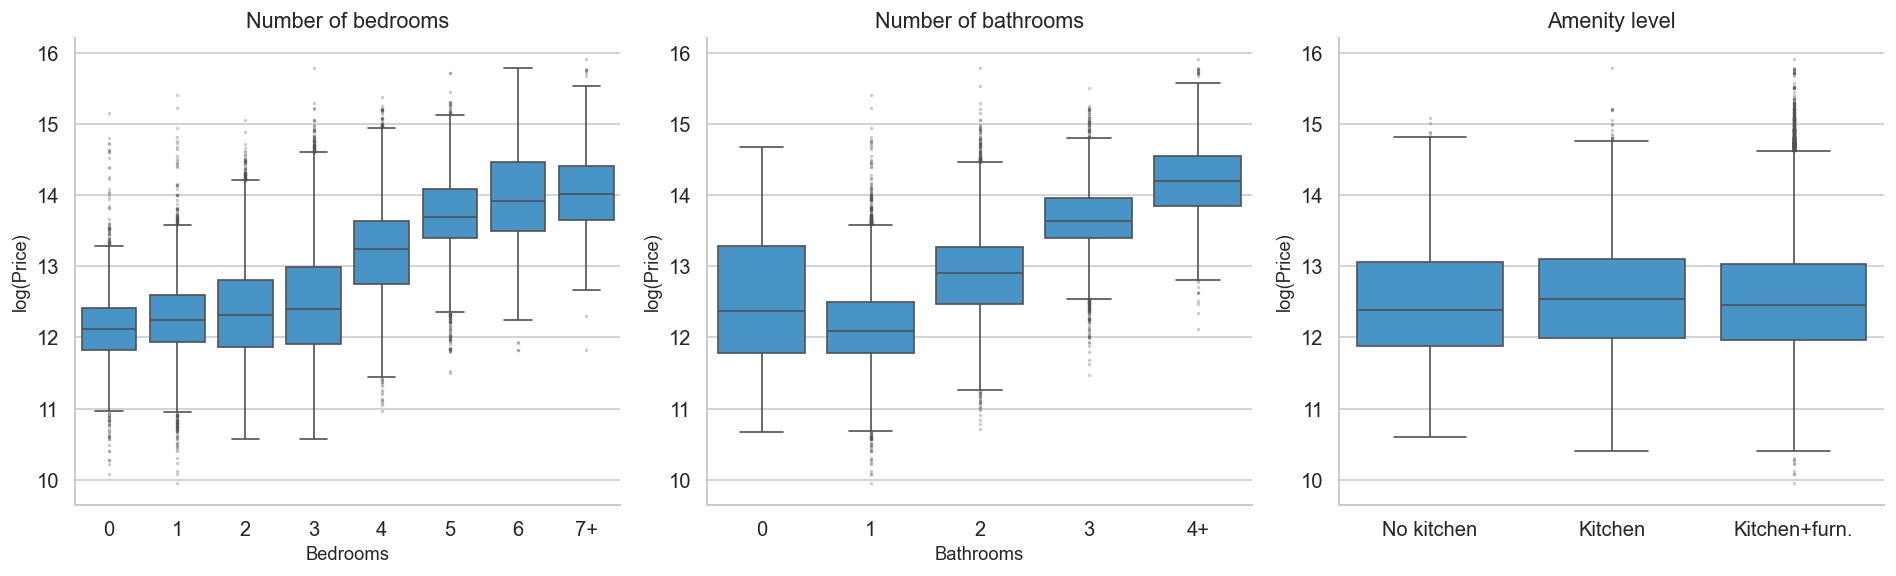

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Bedrooms
room_data = df.copy()
room_data["rooms"] = room_data["ROOMNUMBER"].clip(upper=7).astype(str)
room_data.loc[room_data["ROOMNUMBER"] >= 7, "rooms"] = "7+"
sns.boxplot(x="rooms", y="log_price", data=room_data, ax=axes[0],
            order=[str(i) for i in range(7)] + ["7+"], color="#3498db",
            flierprops=dict(marker=".", markersize=2, alpha=0.3))
axes[0].set_title("Number of bedrooms")
axes[0].set_xlabel("Bedrooms")

# Bathrooms
bath_data = df.copy()
bath_data["baths"] = bath_data["BATHNUMBER"].clip(upper=4).astype(str)
bath_data.loc[bath_data["BATHNUMBER"] >= 4, "baths"] = "4+"
sns.boxplot(x="baths", y="log_price", data=bath_data, ax=axes[1],
            order=[str(i) for i in range(4)] + ["4+"], color="#3498db",
            flierprops=dict(marker=".", markersize=2, alpha=0.3))
axes[1].set_title("Number of bathrooms")
axes[1].set_xlabel("Bathrooms")

# Amenity level
amenity_labels = {1: "No kitchen", 2: "Kitchen", 3: "Kitchen+furn."}
amenity_data = df.copy()
amenity_data["amenity"] = amenity_data["AMENITYID"].map(amenity_labels)
sns.boxplot(x="amenity", y="log_price", data=amenity_data, ax=axes[2],
            order=["No kitchen", "Kitchen", "Kitchen+furn."], color="#3498db",
            flierprops=dict(marker=".", markersize=2, alpha=0.3))
axes[2].set_title("Amenity level")
axes[2].set_xlabel("")

for ax in axes:
    ax.set_ylabel("log(Price)")
    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

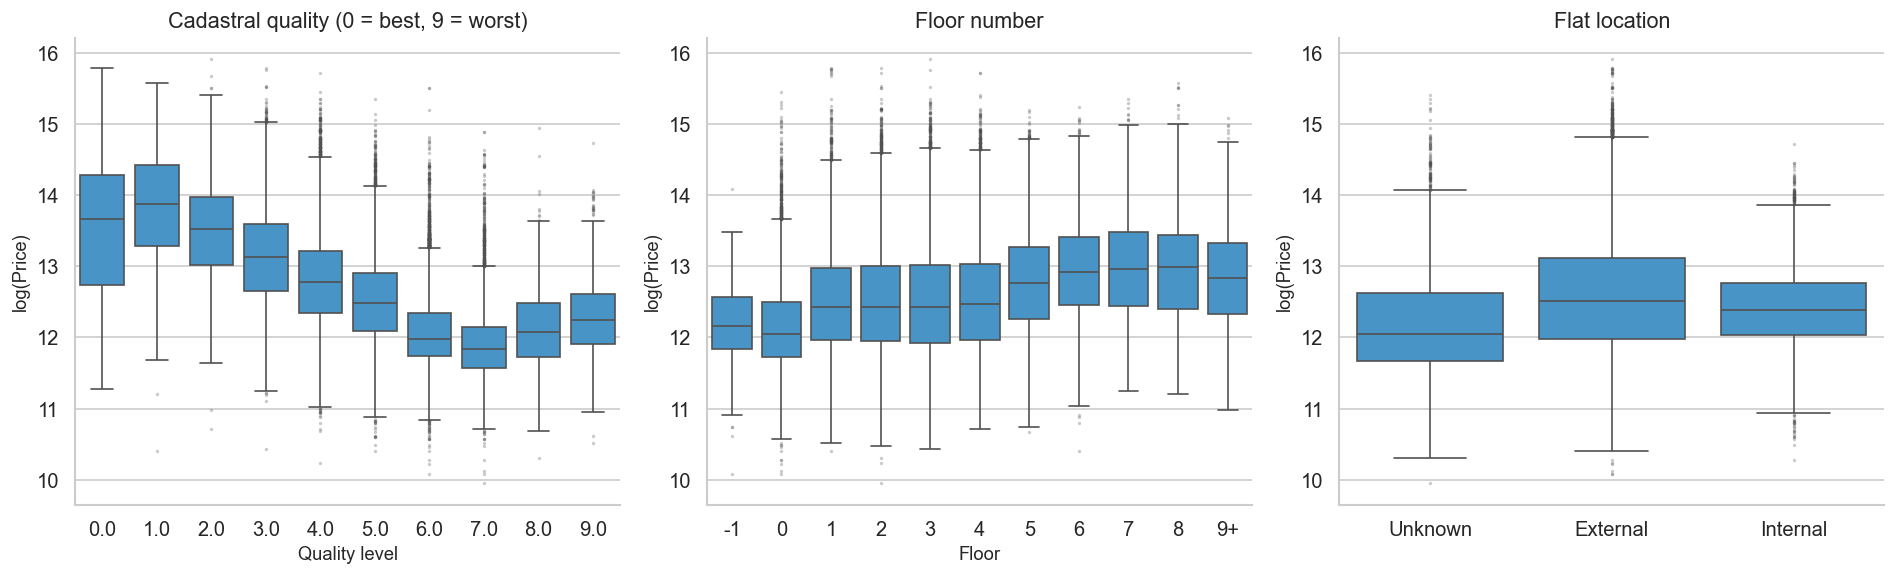

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Cadastral quality
sns.boxplot(x="CADASTRALQUALITYID", y="log_price", data=df, ax=axes[0], color="#3498db",
            flierprops=dict(marker=".", markersize=2, alpha=0.3))
axes[0].set_title("Cadastral quality (0 = best, 9 = worst)")
axes[0].set_xlabel("Quality level")

# Floor number
floor_data = df.copy()
floor_data["floor"] = floor_data["FLOORCLEAN"].clip(-1, 8).astype(int).astype(str)
floor_data.loc[floor_data["FLOORCLEAN"] > 8, "floor"] = "9+"
sns.boxplot(x="floor", y="log_price", data=floor_data, ax=axes[1],
            order=[str(i) for i in range(-1, 9)] + ["9+"], color="#3498db",
            flierprops=dict(marker=".", markersize=2, alpha=0.3))
axes[1].set_title("Floor number")
axes[1].set_xlabel("Floor")

# Flat location
loc_labels = {0: "Unknown", 1: "External", 2: "Internal"}
loc_data = df.copy()
loc_data["location"] = loc_data["FLATLOCATIONID"].map(loc_labels)
sns.boxplot(x="location", y="log_price", data=loc_data, ax=axes[2],
            order=["Unknown", "External", "Internal"], color="#3498db",
            flierprops=dict(marker=".", markersize=2, alpha=0.3))
axes[2].set_title("Flat location")
axes[2].set_xlabel("")

for ax in axes:
    ax.set_ylabel("log(Price)")
    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

BATHNUMBER turns out to be a stronger signal than ROOMNUMBER (r = 0.70 vs 0.46). Each extra bathroom comes with a clear price jump.

CADASTRALQUALITYID has a nice monotonic pattern — lower level means better quality and higher price (r = -0.57). This is one of the most useful features.

ROOMNUMBER goes up slowly until 3 bedrooms and then jumps at 4+, partly because bigger flats just have more rooms.

AMENITYID is almost useless since 94% of listings are level 3. FLOORCLEAN shows that higher floors are pricier, with ground floor being the cheapest. FLATLOCATIONID confirms that "unknown" (0) flats are the cheapest group, so our decision in notebook 01 to keep it as a separate category was correct.

## 3. Binary features vs log(PRICE)

For each binary feature we check how much more (or less) expensive the listings are when the feature is present.

In [7]:
binary_cols = [c for c in df.columns if c.startswith("HAS") or c.startswith("IS") or c.startswith("BUILTTYPEID")]

price_diff = {}
for col in binary_cols:
    median_0 = df.loc[df[col] == 0, "PRICE"].median()
    median_1 = df.loc[df[col] == 1, "PRICE"].median()
    price_diff[col] = ((median_1 - median_0) / median_0) * 100

price_diff = pd.Series(price_diff).sort_values()

readable_bin = {
    "HASTERRACE": "Terrace", "HASLIFT": "Lift", "HASAIRCONDITIONING": "Air conditioning",
    "HASPARKINGSPACE": "Parking",
    "HASNORTHORIENTATION": "North facing", "HASSOUTHORIENTATION": "South facing",
    "HASEASTORIENTATION": "East facing", "HASWESTORIENTATION": "West facing",
    "HASBOXROOM": "Box room", "HASWARDROBE": "Wardrobe", "HASSWIMMINGPOOL": "Swimming pool",
    "HASDOORMAN": "Doorman", "HASGARDEN": "Garden", "ISDUPLEX": "Duplex",
    "ISSTUDIO": "Studio", "ISINTOPFLOOR": "Top floor",
    "BUILTTYPEID_1": "New development",
    "BUILTTYPEID_2": "Second hand, to restore",
    "BUILTTYPEID_3": "Second hand, good condition",
}
labels = [readable_bin.get(c, c) for c in price_diff.index]

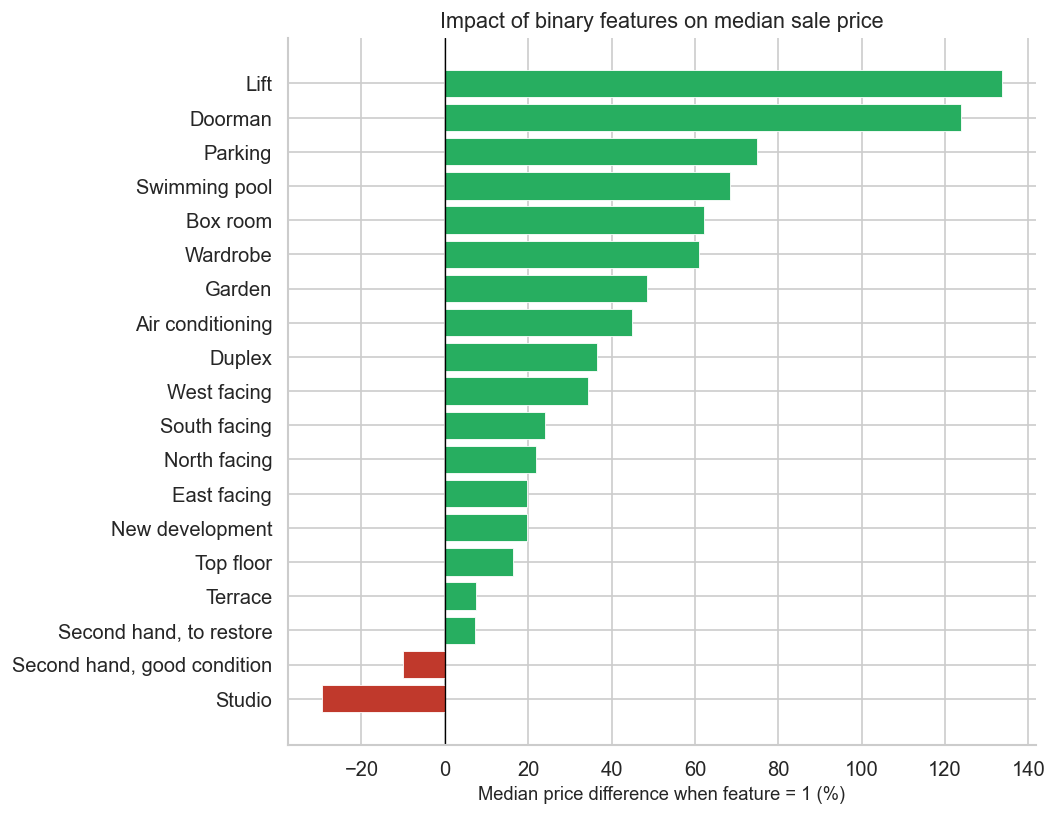

In [8]:
colors = ["#c0392c" if v < 0 else "#27ae60" for v in price_diff]

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(labels, price_diff.values, color=colors, edgecolor="white", linewidth=0.5)
ax.set_xlabel("Median price difference when feature = 1 (%)")
ax.set_title("Impact of binary features on median sale price")
ax.axvline(0, color="black", lw=0.8)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

Having a lift (+134%) or a doorman (+124%) makes the biggest difference — but these are really proxies for building quality rather than the amenity itself. Parking, pool, box room and wardrobe also add a decent premium.

Studios are the only big discount (-29%), which makes sense since they are small.

One odd thing: "second hand to restore" flats are more expensive than "good condition" ones. This is probably because flats that need renovation tend to be in expensive central areas, so it's a location effect, not a condition effect.

These are raw differences though — the model will need to separate size, location and amenity effects properly.

## 4. Correlation analysis

We look at which features correlate most with log(PRICE) and which ones are too correlated with each other (multicollinearity).

In [9]:
numeric_cols = df.select_dtypes(include=[np.number]).columns.drop("PRICE").tolist()
corr = df[numeric_cols].corr()
target_corr = corr["log_price"].drop("log_price").sort_values()

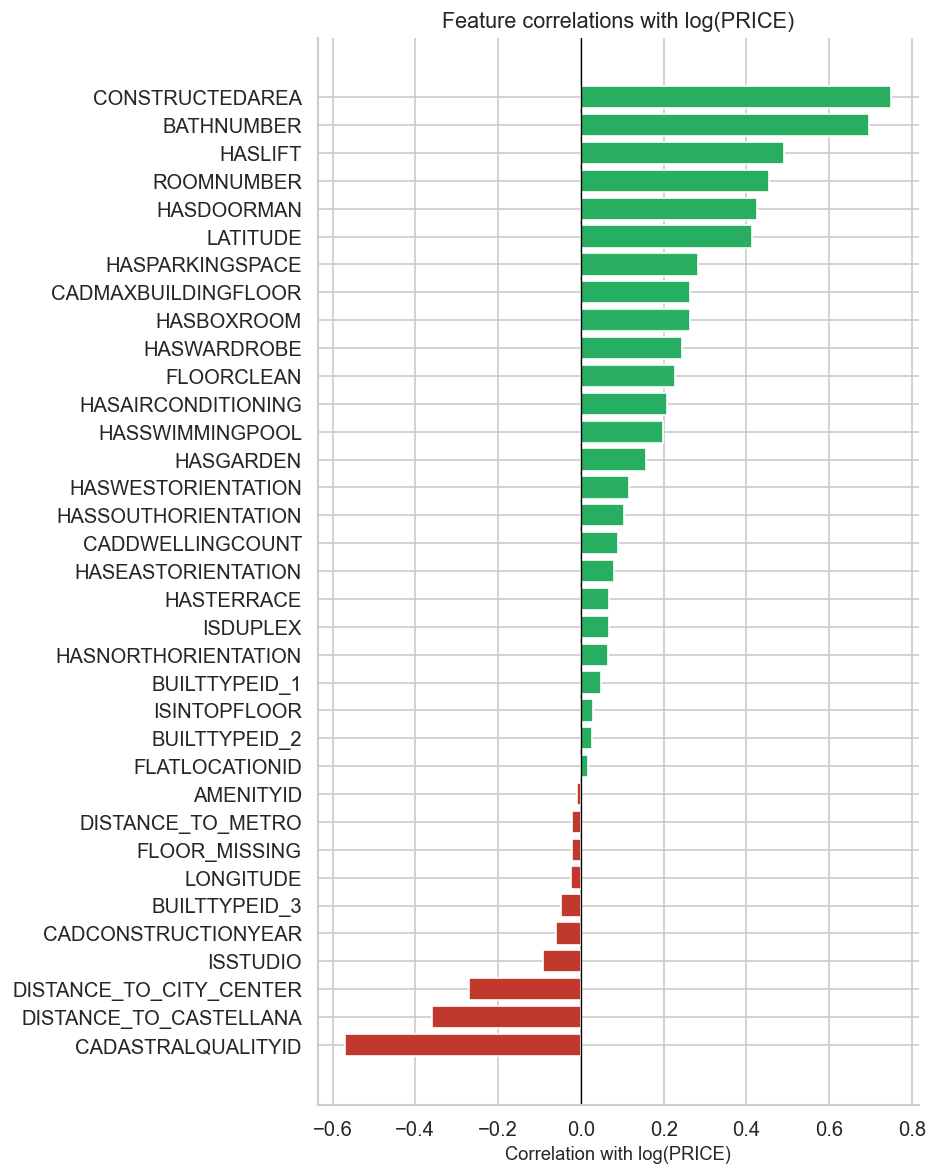

In [10]:
# Correlation of each feature with log(PRICE)
colors = ["#c0392c" if v < 0 else "#27ae60" for v in target_corr.values]

fig, ax = plt.subplots(figsize=(8, 10))
ax.barh(target_corr.index, target_corr.values, color=colors, edgecolor="white")
ax.set_xlabel("Correlation with log(PRICE)")
ax.set_title("Feature correlations with log(PRICE)")
ax.axvline(0, color="black", lw=0.8)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

In [11]:
# Most correlated pairs of features (multicollinearity risk)
feat_corr = corr.drop(index="log_price", columns="log_price").abs()
upper = feat_corr.where(np.triu(np.ones(feat_corr.shape, dtype=bool), k=1))

print("Most correlated pairs of features:")
print(upper.stack().sort_values(ascending=False).head(6).round(3))

Most correlated pairs of features:
BUILTTYPEID_2            BUILTTYPEID_3             0.906
DISTANCE_TO_CITY_CENTER  DISTANCE_TO_CASTELLANA    0.778
CONSTRUCTEDAREA          BATHNUMBER                0.775
HASSWIMMINGPOOL          HASGARDEN                 0.666
CONSTRUCTEDAREA          ROOMNUMBER                0.652
ROOMNUMBER               BATHNUMBER                0.607
dtype: float64


The top predictors are size-related (area 0.75, bathrooms 0.70), then building quality (cadastral quality -0.57, lift 0.49, doorman 0.43), and then location (latitude 0.41, distance to Castellana -0.36).

Some pairs of features are very correlated with each other, which could cause problems in linear models:

- BUILTTYPEID_2 and BUILTTYPEID_3 (r = 0.91) — they are one-hot encoded from the same variable, so we need to drop one in linear models
- DISTANCE_TO_CITY_CENTER and DISTANCE_TO_CASTELLANA (r = 0.78) — both measure centrality
- Area, bathrooms and rooms are all correlated (r = 0.61 to 0.78) — regularisation will help here
- Pool and garden (r = 0.67) tend to appear together in big properties

A few features have very low correlation: AMENITYID, FLOOR_MISSING, CADCONSTRUCTIONYEAR, DISTANCE_TO_METRO and LONGITUDE. Though for CADCONSTRUCTIONYEAR this hides the U-shaped pattern we saw earlier.

## 5. Location and time

The price map of Madrid shows a clear north-south gradient — the northern half (Salamanca, Chamberi) is much more expensive. That's why LATITUDE (r = 0.41) works better than LONGITUDE (which is basically zero). DISTANCE_TO_CASTELLANA captures the same axis.

Prices went up about 9% over 2018 (median price per m2 from 3,260 to 3,560 EUR). It's not huge compared to the variation between properties, but we should include PERIOD as a feature.

## 6. Conclusions

Property prices in Madrid are driven by three groups of features: **size** (CONSTRUCTEDAREA r = 0.75, BATHNUMBER r = 0.70), **building quality** (CADASTRALQUALITYID r = -0.57, lift +134%, doorman +124%), and **location** (LATITUDE r = 0.41, DISTANCE_TO_CASTELLANA r = -0.36). We also found non-linear patterns — CADCONSTRUCTIONYEAR has a U-shape (old and new buildings are expensive, 1960s-80s are cheap) and FLOORCLEAN dips at ground floor — which suggest tree-based models will outperform plain linear regression.

There are multicollinearity issues to watch: BUILTTYPEID dummies (r = 0.91), the two distance variables (r = 0.78), and area/rooms/bathrooms all move together, so regularisation is needed for linear baselines. Plan for modelling: log(PRICE) as target, stratify train/test by PERIOD, start with Ridge/Lasso, then move to tree-based models. We keep 30 features.